In [2]:

import pandas as pd

# Load the dataset
df = pd.read_csv(
    "../data/raw/longitudinal.csv",
    low_memory=False
)

# Display first 5 records
print(df.head())

# Check number of rows and columns
print(df.shape)

# Display column names
print(df.columns.tolist())

# Check data types
print(df.dtypes)


       event_id   patient_id encounter_id  event_date event_time  \
0  EVT000000001  AGP00000001          NaN  2025-04-27   14:42:01   
1  EVT000000002  AGP00000001  ENC00000001  2025-04-27   14:53:54   
2  EVT000000003  AGP00000001  ENC00000001  2025-04-27   14:53:54   
3  EVT000000004  AGP00000001  ENC00000001  2025-04-27   15:06:34   
4  EVT000000005  AGP00000001  ENC00000001  2025-04-27   15:50:32   

                event_type event_category source_system  \
0       patient_registered   registration           EHR   
1        encounter_created   registration           EHR   
2               ed_arrival      emergency           EHR   
3                ed_triage      emergency           EHR   
4  ed_physician_assessment      emergency           EHR   

            destination_system            department  ... transfer_reason  \
0  Hospital Information System          Registration  ...             NaN   
1  Hospital Information System  Emergency Department  ...             NaN   
2  Ho

In [3]:

# Count different event types
event_counts = df['event_type'].value_counts()

# Display all event types
print(event_counts.to_string())

# Count the total number of unique event types
print("\nTotal event types:", df['event_type'].nunique())


event_type
medication_administered             90366
lab_order_placed                    70635
lab_result_reported                 70635
encounter_created                   66872
encounter_closed                    57490
patient_registered                  50000
billing_charge_generated            41491
billing_transmitted                 41491
medication_order_placed             38653
medication_dispensed                36343
imaging_order_placed                15366
imaging_report_finalized            15366
message_transmission                12180
ed_physician_assessment              6610
ed_triage                            6610
ed_disposition                       6610
ed_treatment                         6610
ed_arrival                           6610
discharge                            4225
clinical_assessment                  4225
ward_assignment                      4225
admission                            4225
insurance_updated                    3314
medication_administrati

In [4]:

# Filter laboratory-related event categories
lab_df = df[
    df['event_category'].str.contains(
        'laboratory|lab',
        case=False,
        na=False
    )
]

print("Total laboratory event records:", len(lab_df))

print("\nLaboratory event types:")
print(lab_df['event_type'].value_counts().to_string())


Total laboratory event records: 141270

Laboratory event types:
event_type
lab_order_placed       70635
lab_result_reported    70635


In [5]:

# Filter laboratory orders
lab_orders = df[
    df['event_type'] == 'lab_order_placed'
]

# Display the first 10 laboratory orders
print(lab_orders.head(10))

# Count unique laboratory orders
print(
    "Unique order IDs:",
    lab_orders['order_id'].nunique()
)


        event_id   patient_id encounter_id  event_date event_time  \
5   EVT000000006  AGP00000001  ENC00000001  2025-04-27   16:04:51   
7   EVT000000008  AGP00000001  ENC00000001  2025-04-27   18:20:15   
9   EVT000000010  AGP00000001  ENC00000001  2025-04-27   21:14:10   
17  EVT000000018  AGP00000001  ENC00000002  2026-05-08   15:03:35   
25  EVT000000026  AGP00000002  ENC00000003  2026-05-24   09:15:30   
33  EVT000000034  AGP00000003  ENC00000004  2024-05-30   20:42:08   
42  EVT000000043  AGP00000005  ENC00000006  2025-07-17   08:31:45   
55  EVT000000056  AGP00000007  ENC00000008  2024-01-09   07:06:37   
71  EVT000000072  AGP00000010  ENC00000011  2024-06-21   20:19:31   
91  EVT000000092  AGP00000013  ENC00000015  2026-04-12   22:10:37   

          event_type event_category source_system destination_system  \
5   lab_order_placed     laboratory           EHR                LIS   
7   lab_order_placed     laboratory           EHR                LIS   
9   lab_order_placed    

In [6]:

# Count missing values in every column
missing_values = df.isnull().sum()

# Calculate missing value percentage
missing_percentage = (
    df.isnull().mean() * 100
).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

# Show columns with missing values
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
]

print(
    missing_summary.sort_values(
        by='Missing Percentage',
        ascending=False
    )
)


                        Missing Values  Missing Percentage
request_time                    679167               99.80
transfer_id                     678223               99.66
to_department                   678223               99.66
bed_category                    678223               99.66
transfer_status                 678223               99.66
completion_time                 678223               99.66
from_department                 678223               99.66
transfer_reason                 678223               99.66
procedure_category              677819               99.60
procedure_id                    677819               99.60
completion_status               677819               99.60
discontinuation_reason          676382               99.39
acknowledgement_status          667712               98.12
retry_count                     667447               98.08
error_status                    667447               98.08
message_type                    667447               98.

In [7]:

# Columns important for LabPulse
important_columns = [
    'order_id',
    'test_name',
    'specimen_type',
    'collection_time',
    'processing_time',
    'result_time',
    'result_id',
    'result_status'
]

# Separate laboratory orders
lab_orders = df[
    df['event_type'] == 'lab_order_placed'
]

# Separate laboratory results
lab_results = df[
    df['event_type'] == 'lab_result_reported'
]

# Check missing values in laboratory orders
order_missing = (
    lab_orders[important_columns]
    .isnull()
    .mean()
    .mul(100)
    .round(2)
)

print("LABORATORY ORDER MISSING VALUE PERCENTAGE")
print(order_missing)

# Check missing values in laboratory results
result_missing = (
    lab_results[important_columns]
    .isnull()
    .mean()
    .mul(100)
    .round(2)
)

print("\nLABORATORY RESULT MISSING VALUE PERCENTAGE")
print(result_missing)


LABORATORY ORDER MISSING VALUE PERCENTAGE
order_id             0.0
test_name            0.0
specimen_type        0.0
collection_time    100.0
processing_time    100.0
result_time        100.0
result_id          100.0
result_status        0.0
dtype: float64

LABORATORY RESULT MISSING VALUE PERCENTAGE
order_id           0.00
test_name          0.00
specimen_type      0.00
collection_time    0.00
processing_time    2.09
result_time        0.00
result_id          0.00
result_status      0.00
dtype: float64


In [8]:
# Find laboratory result records
# where processing_time is missing

missing_processing = lab_results[
    lab_results['processing_time'].isnull()
]

print("Records with missing processing time:",
      len(missing_processing))

print("\nFirst 10 records:")
print(
    missing_processing[
        [
            'order_id',
            'test_name',
            'specimen_type',
            'collection_time',
            'processing_time',
            'result_time',
            'result_status'
        ]
    ].head(10).to_string(index=False)
)

Records with missing processing time: 1473

First 10 records:
   order_id  test_name specimen_type     collection_time processing_time         result_time result_status
ORD00000066        CBC         Blood 2025-11-23 11:57:14             NaN 2025-11-23 13:46:17         final
ORD00000121 Hemoglobin         Blood 2024-08-03 17:28:01             NaN 2024-08-03 20:20:55         final
ORD00000219        CRP         Blood 2025-12-26 10:26:28             NaN 2025-12-26 12:40:59         final
ORD00000252 Creatinine         Blood 2026-01-11 06:54:05             NaN 2026-01-11 08:36:56         final
ORD00000273  Bilirubin         Blood 2025-04-24 12:11:22             NaN 2025-04-24 13:29:49         final
ORD00000326   Troponin         Blood 2024-03-25 12:20:25             NaN 2024-03-25 15:39:21         final
ORD00000557        AST         Blood 2025-01-13 15:24:58             NaN 2025-01-13 17:13:04         final
ORD00000612        WBC         Blood 2026-06-06 07:34:27             NaN 2026-06-0

In [9]:
missing_by_test = (
    missing_processing['test_name']
    .value_counts()
)

print("Missing processing timestamps by test:")
print(missing_by_test.to_string())

Missing processing timestamps by test:
test_name
Platelets     121
Sodium        121
eGFR          118
Hemoglobin    111
Troponin      111
Bilirubin     108
Creatinine    106
AST           103
Potassium     101
WBC           100
CRP            99
Glucose        97
ALT            92
CBC            85


In [10]:
# Count total records for each test
total_by_test = lab_results['test_name'].value_counts()

# Count missing processing timestamps for each test
missing_by_test = (
    missing_processing['test_name'].value_counts()
)

# Combine both counts into one DataFrame
test_missing_summary = pd.DataFrame({
    'Total Records': total_by_test,
    'Missing Records': missing_by_test
})

# Calculate missing percentage
test_missing_summary['Missing Percentage'] = (
    test_missing_summary['Missing Records']
    / test_missing_summary['Total Records'] * 100
).round(2)

# Sort from highest to lowest missing percentage
test_missing_summary = test_missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

print(test_missing_summary.to_string())

            Total Records  Missing Records  Missing Percentage
test_name                                                     
Sodium               4974              121                2.43
Platelets            5074              121                2.38
eGFR                 5102              118                2.31
Hemoglobin           5141              111                2.16
Bilirubin            5033              108                2.15
Troponin             5157              111                2.15
Creatinine           4997              106                2.12
Potassium            4909              101                2.06
AST                  5006              103                2.06
CRP                  4998               99                1.98
WBC                  5070              100                1.97
Glucose              5016               97                1.93
ALT                  5115               92                1.80
CBC                  5043               85             

In [11]:
# Check the current data types
print("Before conversion:")
print(lab_results[
    ['collection_time', 'result_time']
].dtypes)

# Convert timestamps into datetime format
lab_results['collection_time'] = pd.to_datetime(
    lab_results['collection_time'],
    errors='coerce'
)

lab_results['result_time'] = pd.to_datetime(
    lab_results['result_time'],
    errors='coerce'
)

# Check data types again
print("\nAfter conversion:")
print(lab_results[
    ['collection_time', 'result_time']
].dtypes)

Before conversion:
collection_time    object
result_time        object
dtype: object

After conversion:
collection_time    datetime64[ns]
result_time        datetime64[ns]
dtype: object


C:\Users\Mohit\AppData\Local\Temp\ipykernel_13356\3193347002.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lab_results['collection_time'] = pd.to_datetime(
C:\Users\Mohit\AppData\Local\Temp\ipykernel_13356\3193347002.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lab_results['result_time'] = pd.to_datetime(


In [12]:
# Create an independent copy of laboratory result records
lab_results = df[
    df['event_type'] == 'lab_result_reported'
].copy()

# Convert collection_time into datetime format
lab_results['collection_time'] = pd.to_datetime(
    lab_results['collection_time'],
    errors='coerce'
)

# Convert result_time into datetime format
lab_results['result_time'] = pd.to_datetime(
    lab_results['result_time'],
    errors='coerce'
)

# Verify the conversion
print(lab_results[
    ['collection_time', 'result_time']
].dtypes)

collection_time    datetime64[ns]
result_time        datetime64[ns]
dtype: object


In [13]:
# Calculate turnaround time
lab_results['tat'] = (
    lab_results['result_time']
    - lab_results['collection_time']
)

# Convert TAT into minutes
lab_results['tat_minutes'] = (
    lab_results['tat'].dt.total_seconds() / 60
)

# Display sample records
print(
    lab_results[
        [
            'test_name',
            'collection_time',
            'result_time',
            'tat',
            'tat_minutes'
        ]
    ].head(10).to_string(index=False)
)

 test_name     collection_time         result_time             tat  tat_minutes
Hemoglobin 2025-04-27 16:13:37 2025-04-27 18:20:15 0 days 02:06:38   126.633333
       CRP 2025-04-27 18:59:59 2025-04-27 21:14:10 0 days 02:14:11   134.183333
    Sodium 2025-04-27 23:00:18 2025-04-28 02:05:26 0 days 03:05:08   185.133333
 Potassium 2026-05-08 16:13:08 2026-05-08 18:08:39 0 days 01:55:31   115.516667
 Potassium 2026-05-24 10:26:26 2026-05-24 12:29:18 0 days 02:02:52   122.866667
Hemoglobin 2024-05-30 20:57:42 2024-05-30 23:41:05 0 days 02:43:23   163.383333
 Potassium 2025-07-17 09:27:36 2025-07-17 11:34:56 0 days 02:07:20   127.333333
 Bilirubin 2024-01-09 07:58:35 2024-01-09 10:30:41 0 days 02:32:06   152.100000
       AST 2024-06-21 20:30:50 2024-06-21 22:43:26 0 days 02:12:36   132.600000
 Platelets 2026-04-12 23:27:46 2026-04-13 01:27:06 0 days 01:59:20   119.333333


In [14]:
# Check for missing TAT values
print("Missing TAT values:",
      lab_results['tat_minutes'].isnull().sum())

# Check for negative TAT values
print("Negative TAT values:",
      (lab_results['tat_minutes'] < 0).sum())

# Get statistical summary of TAT
print("\nTAT Statistical Summary:")
print(lab_results['tat_minutes'].describe())

Missing TAT values: 0
Negative TAT values: 0

TAT Statistical Summary:
count    70635.000000
mean       127.930680
std         47.570372
min         25.300000
25%         91.416667
50%        128.250000
75%        164.116667
max        239.533333
Name: tat_minutes, dtype: float64


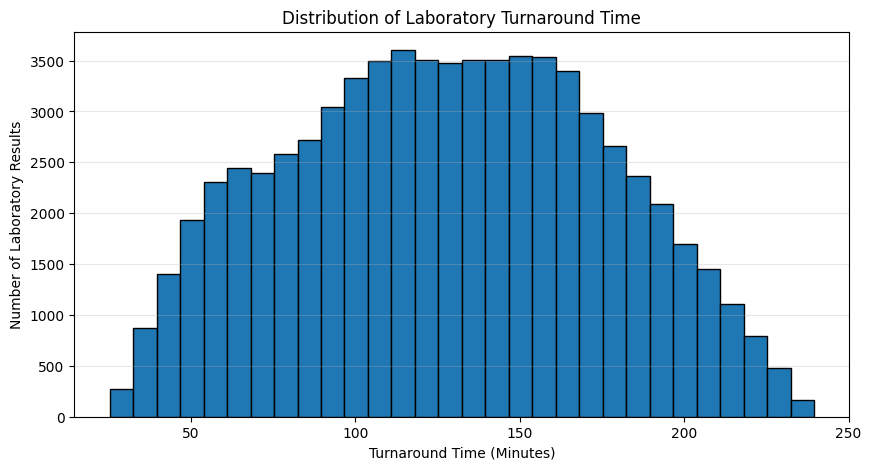

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    lab_results['tat_minutes'],
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Laboratory Turnaround Time')
plt.xlabel('Turnaround Time (Minutes)')
plt.ylabel('Number of Laboratory Results')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [16]:
tat_by_test = (
    lab_results.groupby('test_name')['tat_minutes']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
    .sort_values(by='mean', ascending=False)
)

print(tat_by_test.to_string())

            count    mean  median    min     max
test_name                                       
Platelets    5074  129.02  128.82  26.35  238.12
Bilirubin    5033  128.74  128.58  25.67  237.80
eGFR         5102  128.53  129.00  27.23  239.03
CBC          5043  128.28  129.45  27.48  238.08
CRP          4998  128.27  128.14  26.03  237.32
Creatinine   4997  128.18  129.03  28.87  236.58
Sodium       4974  128.14  128.79  26.22  239.42
Hemoglobin   5141  128.05  128.30  26.92  238.08
Glucose      5016  127.60  127.73  27.33  239.35
AST          5006  127.60  127.68  25.37  238.98
Potassium    4909  127.59  128.62  27.85  239.22
Troponin     5157  127.23  127.62  26.75  239.53
WBC          5070  127.15  126.57  25.30  236.47
ALT          5115  126.68  126.97  27.23  238.92


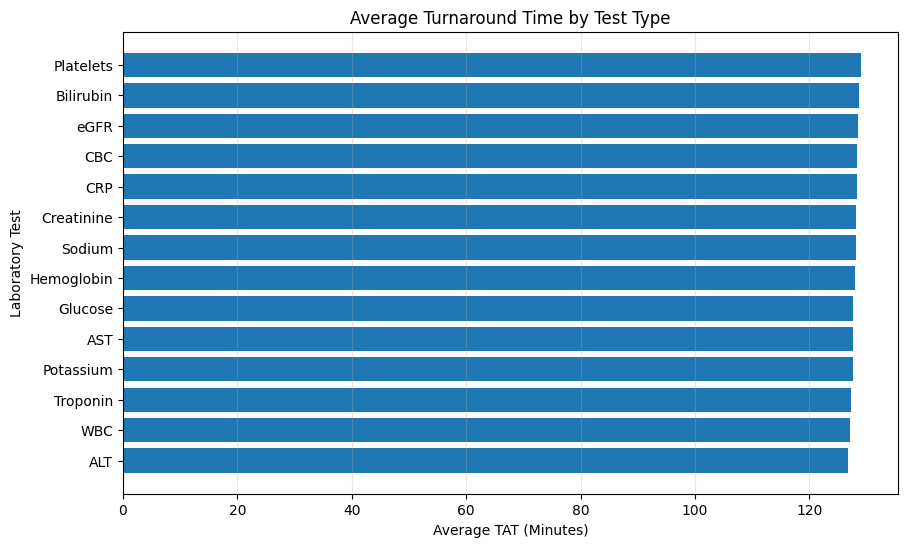

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    tat_by_test.index,
    tat_by_test['mean']
)

plt.title('Average Turnaround Time by Test Type')
plt.xlabel('Average TAT (Minutes)')
plt.ylabel('Laboratory Test')

plt.gca().invert_yaxis()

plt.grid(axis='x', alpha=0.3)
plt.show()

In [18]:
slowest_results = lab_results.sort_values(
    by='tat_minutes',
    ascending=False
)

print(
    slowest_results[
        [
            'order_id',
            'test_name',
            'collection_time',
            'result_time',
            'tat_minutes'
        ]
    ].head(10).to_string(index=False)
)

   order_id test_name     collection_time         result_time  tat_minutes
ORD00050973  Troponin 2026-03-17 23:08:52 2026-03-18 03:08:24   239.533333
ORD00024740    Sodium 2024-05-11 16:30:59 2024-05-11 20:30:24   239.416667
ORD00041076   Glucose 2026-01-30 08:55:05 2026-01-30 12:54:26   239.350000
ORD00044643 Potassium 2024-05-21 20:53:04 2024-05-22 00:52:17   239.216667
ORD00122354      eGFR 2024-10-12 15:43:55 2024-10-12 19:42:57   239.033333
ORD00064131    Sodium 2025-11-03 21:40:28 2025-11-04 01:39:28   239.000000
ORD00000829       AST 2024-06-11 07:23:06 2024-06-11 11:22:05   238.983333
ORD00023814       AST 2024-05-04 17:20:44 2024-05-04 21:19:41   238.950000
ORD00052248       ALT 2024-09-16 13:51:51 2024-09-16 17:50:46   238.916667
ORD00022578   Glucose 2024-01-10 15:17:06 2024-01-10 19:15:29   238.383333


In [19]:
# Filter records with TAT of 230 minutes or more
long_tat_records = lab_results[
    lab_results['tat_minutes'] >= 230
]

# Count these records
print("Records with TAT >= 230 minutes:",
      len(long_tat_records))

# Calculate their percentage
percentage = (
    len(long_tat_records) / len(lab_results)
) * 100

print("Percentage of total results:",
      round(percentage, 2), "%")

Records with TAT >= 230 minutes: 318
Percentage of total results: 0.45 %


In [20]:
long_tat_by_test = (
    long_tat_records['test_name']
    .value_counts()
)

print("Long TAT records by test type:")
print(long_tat_by_test.to_string())

Long TAT records by test type:
test_name
CBC           31
AST           28
CRP           28
Bilirubin     27
Platelets     24
Hemoglobin    23
ALT           22
Troponin      22
WBC           22
Glucose       21
Sodium        20
Potassium     17
Creatinine    17
eGFR          16


In [21]:
# Count long-TAT records for each test
long_tat_counts = (
    long_tat_records['test_name'].value_counts()
)

# Create a summary using total and long-TAT counts
long_tat_summary = pd.DataFrame({
    'Total Records': tat_by_test['count'],
    'Long TAT Records': long_tat_counts
})

# Calculate long-TAT percentage
long_tat_summary['Long TAT Percentage'] = (
    long_tat_summary['Long TAT Records']
    / long_tat_summary['Total Records'] * 100
).round(2)

# Sort by percentage from highest to lowest
long_tat_summary = long_tat_summary.sort_values(
    by='Long TAT Percentage',
    ascending=False
)

print(long_tat_summary.to_string())

            Total Records  Long TAT Records  Long TAT Percentage
test_name                                                       
CBC                  5043                31                 0.61
AST                  5006                28                 0.56
CRP                  4998                28                 0.56
Bilirubin            5033                27                 0.54
Platelets            5074                24                 0.47
Hemoglobin           5141                23                 0.45
WBC                  5070                22                 0.43
ALT                  5115                22                 0.43
Troponin             5157                22                 0.43
Glucose              5016                21                 0.42
Sodium               4974                20                 0.40
Potassium            4909                17                 0.35
Creatinine           4997                17                 0.34
eGFR                 5102

In [22]:
tat_variability = (
    lab_results.groupby('test_name')['tat_minutes']
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .round(2)
    .sort_values(by='std', ascending=False)
)

print(tat_variability.to_string())

              mean  median    std    min     max
test_name                                       
Sodium      128.14  128.79  48.23  26.22  239.42
CRP         128.27  128.14  48.17  26.03  237.32
WBC         127.15  126.57  48.09  25.30  236.47
Platelets   129.02  128.82  48.07  26.35  238.12
Potassium   127.59  128.62  47.76  27.85  239.22
ALT         126.68  126.97  47.64  27.23  238.92
Hemoglobin  128.05  128.30  47.46  26.92  238.08
Bilirubin   128.74  128.58  47.44  25.67  237.80
CBC         128.28  129.45  47.37  27.48  238.08
AST         127.60  127.68  47.31  25.37  238.98
Glucose     127.60  127.73  47.23  27.33  239.35
Troponin    127.23  127.62  47.15  26.75  239.53
Creatinine  128.18  129.03  47.11  28.87  236.58
eGFR        128.53  129.00  46.96  27.23  239.03


In [23]:
tat_variability['cv_percentage'] = (
    tat_variability['std']
    / tat_variability['mean']
) * 100

tat_variability['cv_percentage'] = (
    tat_variability['cv_percentage'].round(2)
)

tat_variability = tat_variability.sort_values(
    by='cv_percentage',
    ascending=False
)

print(tat_variability.to_string())

              mean  median    std    min     max  cv_percentage
test_name                                                      
WBC         127.15  126.57  48.09  25.30  236.47          37.82
Sodium      128.14  128.79  48.23  26.22  239.42          37.64
ALT         126.68  126.97  47.64  27.23  238.92          37.61
CRP         128.27  128.14  48.17  26.03  237.32          37.55
Potassium   127.59  128.62  47.76  27.85  239.22          37.43
Platelets   129.02  128.82  48.07  26.35  238.12          37.26
AST         127.60  127.68  47.31  25.37  238.98          37.08
Hemoglobin  128.05  128.30  47.46  26.92  238.08          37.06
Troponin    127.23  127.62  47.15  26.75  239.53          37.06
Glucose     127.60  127.73  47.23  27.33  239.35          37.01
CBC         128.28  129.45  47.37  27.48  238.08          36.93
Bilirubin   128.74  128.58  47.44  25.67  237.80          36.85
Creatinine  128.18  129.03  47.11  28.87  236.58          36.75
eGFR        128.53  129.00  46.96  27.23

In [24]:
lab_results['collection_date'] = (
    lab_results['collection_time'].dt.date
)

daily_tat = (
    lab_results.groupby('collection_date')['tat_minutes']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

print(daily_tat.head(10).to_string())

                 count    mean  median
collection_date                       
2024-01-01          62  129.60  126.72
2024-01-02          40  124.29  129.10
2024-01-03          37  122.81  114.27
2024-01-04          68  136.01  138.02
2024-01-05          72  117.60  112.28
2024-01-06          40  123.27  115.93
2024-01-07          82  129.64  124.45
2024-01-08          65  131.59  139.62
2024-01-09          76  133.01  132.34
2024-01-10          93  118.18  117.02


In [25]:
# 10 days with the highest average TAT
highest_tat_days = daily_tat.sort_values(
    by='mean',
    ascending=False
).head(10)

print("TOP 10 DAYS WITH HIGHEST AVERAGE TAT")
print(highest_tat_days.to_string())


# 10 days with the lowest average TAT
lowest_tat_days = daily_tat.sort_values(
    by='mean',
    ascending=True
).head(10)

print("\nTOP 10 DAYS WITH LOWEST AVERAGE TAT")
print(lowest_tat_days.to_string())

TOP 10 DAYS WITH HIGHEST AVERAGE TAT
                 count    mean  median
collection_date                       
2026-06-27          20  153.73  152.16
2026-02-08          67  145.13  150.15
2025-10-20          66  144.77  150.07
2025-06-10          99  144.71  147.95
2026-06-29          13  144.46  136.75
2024-07-11          64  143.94  139.70
2026-05-02          73  143.93  150.48
2026-04-04          74  143.85  147.22
2025-04-09          80  143.32  151.59
2025-05-02          75  142.93  147.88

TOP 10 DAYS WITH LOWEST AVERAGE TAT
                 count    mean  median
collection_date                       
2026-07-04           1   91.78   91.78
2024-09-24          74  109.93  105.01
2025-12-19          91  111.07  116.00
2024-12-11          89  111.48  110.77
2025-09-18          77  111.97  108.55
2025-10-13          81  112.41  104.32
2026-05-19          92  112.52  113.61
2026-02-15          69  112.53  106.42
2026-04-13          75  112.60  111.27
2025-05-09          88  113.1

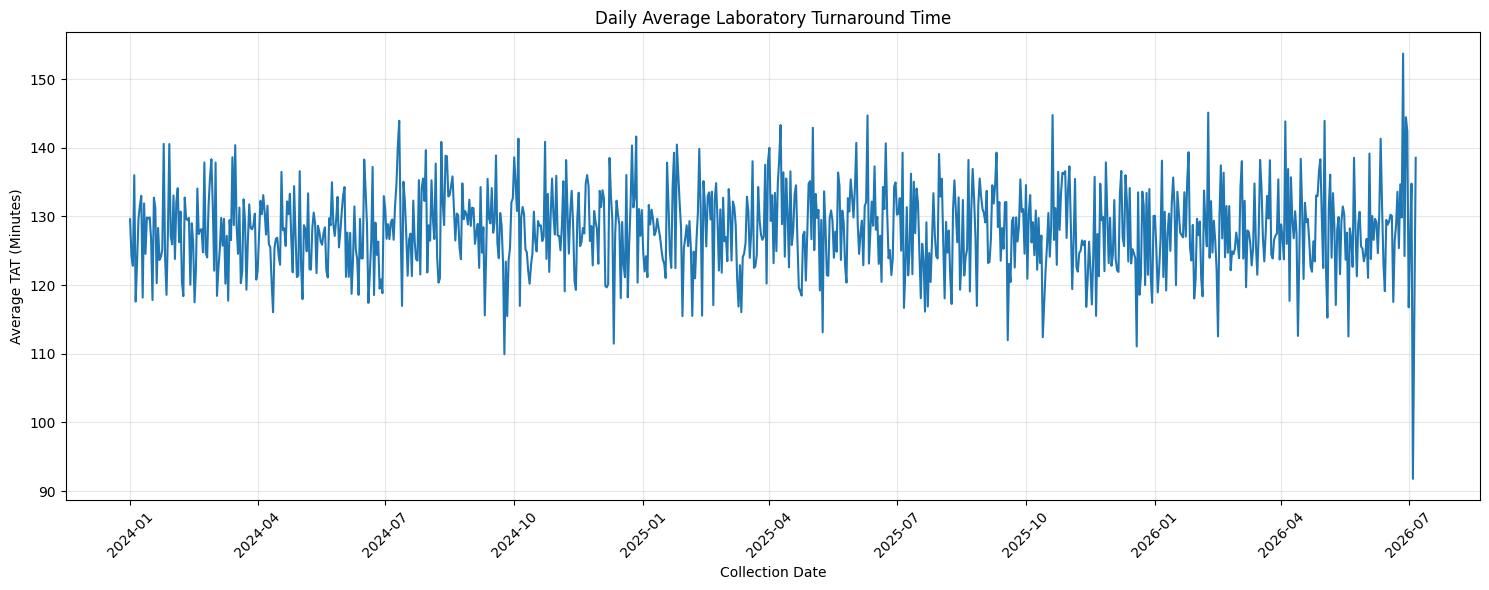

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    daily_tat.index,
    daily_tat['mean']
)

plt.title('Daily Average Laboratory Turnaround Time')
plt.xlabel('Collection Date')
plt.ylabel('Average TAT (Minutes)')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
daily_analysis = daily_tat.copy()

daily_analysis = daily_analysis.rename(
    columns={
        'count': 'daily_sample_volume',
        'mean': 'average_tat',
        'median': 'median_tat'
    }
)

print(daily_analysis.head(10).to_string())

                 daily_sample_volume  average_tat  median_tat
collection_date                                              
2024-01-01                        62       129.60      126.72
2024-01-02                        40       124.29      129.10
2024-01-03                        37       122.81      114.27
2024-01-04                        68       136.01      138.02
2024-01-05                        72       117.60      112.28
2024-01-06                        40       123.27      115.93
2024-01-07                        82       129.64      124.45
2024-01-08                        65       131.59      139.62
2024-01-09                        76       133.01      132.34
2024-01-10                        93       118.18      117.02


In [28]:
correlation = daily_analysis[
    ['daily_sample_volume', 'average_tat']
].corr()

print("Correlation between daily sample volume and average TAT:")
print(correlation)

Correlation between daily sample volume and average TAT:
                     daily_sample_volume  average_tat
daily_sample_volume             1.000000    -0.085627
average_tat                    -0.085627     1.000000


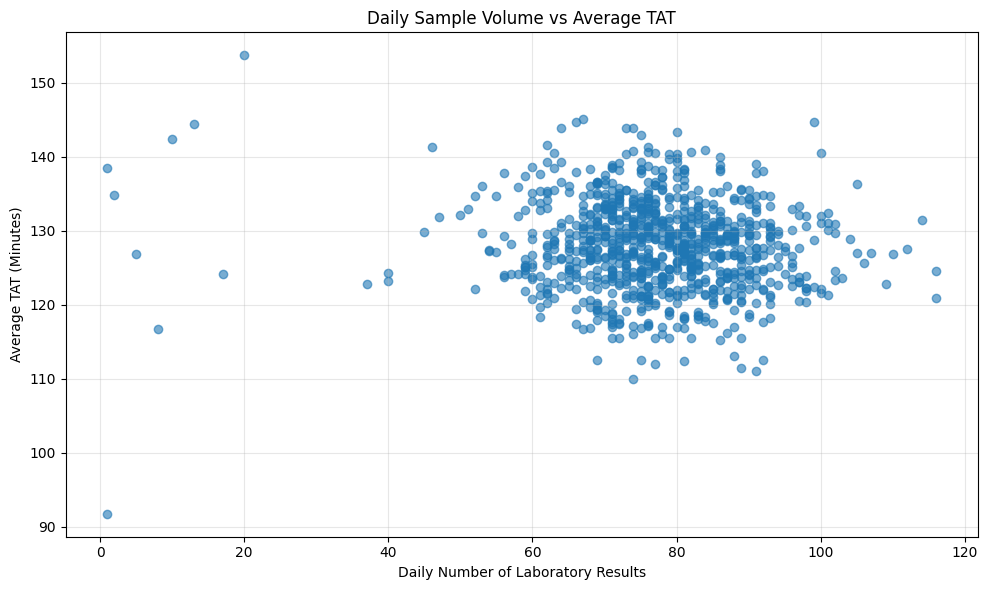

In [29]:
plt.figure(figsize=(10, 6))

plt.scatter(
    daily_analysis['daily_sample_volume'],
    daily_analysis['average_tat'],
    alpha=0.6
)

plt.title('Daily Sample Volume vs Average TAT')
plt.xlabel('Daily Number of Laboratory Results')
plt.ylabel('Average TAT (Minutes)')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
lab_results['collection_hour'] = (
    lab_results['collection_time'].dt.hour
)

hourly_volume = (
    lab_results.groupby('collection_hour')
    .size()
    .reset_index(name='sample_count')
)

print(hourly_volume.to_string(index=False))

 collection_hour  sample_count
               0          1698
               1          1463
               2          1259
               3          1146
               4           946
               5           952
               6          1198
               7          2232
               8          3035
               9          3360
              10          3580
              11          3767
              12          3867
              13          4001
              14          3906
              15          3925
              16          3977
              17          3906
              18          4014
              19          4071
              20          3852
              21          4012
              22          3780
              23          2688


In [31]:
peak_hours = hourly_volume.sort_values(
    by='sample_count',
    ascending=False
)

print(peak_hours.head(10).to_string(index=False))

 collection_hour  sample_count
              19          4071
              18          4014
              21          4012
              13          4001
              16          3977
              15          3925
              17          3906
              14          3906
              12          3867
              20          3852


In [32]:
hourly_tat = (
    lab_results.groupby('collection_hour')['tat_minutes']
    .agg(['count', 'mean', 'median'])
    .round(2)
    .sort_values(by='mean', ascending=False)
)

print(hourly_tat.to_string())

                 count    mean  median
collection_hour                       
2                 1259  134.02  135.85
4                  946  132.53  131.27
6                 1198  131.78  132.06
5                  952  130.95  128.99
3                 1146  130.45  130.02
7                 2232  130.26  131.45
1                 1463  128.94  128.30
8                 3035  128.82  128.98
17                3906  128.17  128.20
13                4001  128.16  128.87
9                 3360  127.90  128.75
20                3852  127.85  128.47
0                 1698  127.82  126.87
19                4071  127.78  127.93
21                4012  127.69  128.98
10                3580  127.66  127.78
18                4014  127.44  127.73
12                3867  127.16  127.45
22                3780  127.02  128.31
11                3767  127.00  127.22
15                3925  126.89  126.60
16                3977  126.86  127.82
23                2688  126.83  124.99
14                3906  1

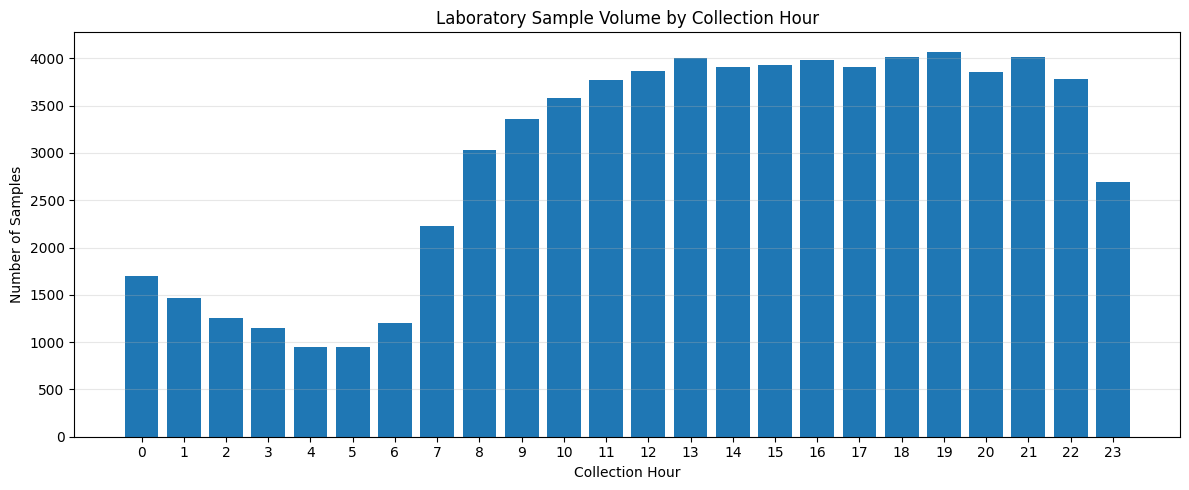

In [34]:
plt.figure(figsize=(12, 5))

plt.bar(
    hourly_volume['collection_hour'],
    hourly_volume['sample_count']
)

plt.title('Laboratory Sample Volume by Collection Hour')
plt.xlabel('Collection Hour')
plt.ylabel('Number of Samples')

plt.xticks(range(24))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

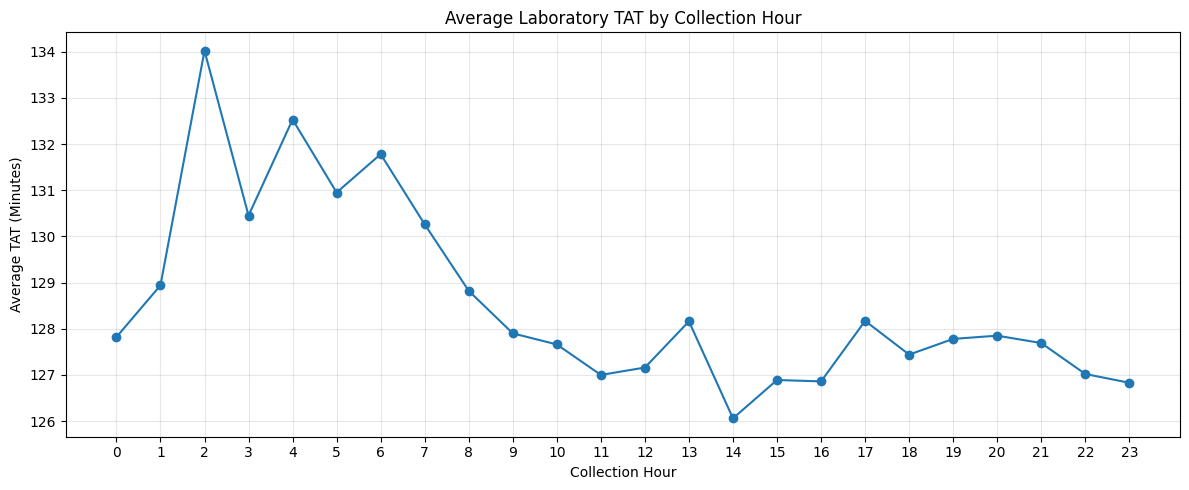

In [35]:
hourly_tat_plot = hourly_tat.sort_index()

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_tat_plot.index,
    hourly_tat_plot['mean'],
    marker='o'
)

plt.title('Average Laboratory TAT by Collection Hour')
plt.xlabel('Collection Hour')
plt.ylabel('Average TAT (Minutes)')

plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
hourly_correlation = hourly_tat[
    ['count', 'mean']
].corr()

print(hourly_correlation)

          count      mean
count  1.000000 -0.817865
mean  -0.817865  1.000000


In [37]:
lab_results['day_of_week'] = (
    lab_results['collection_time'].dt.day_name()
)

print(
    lab_results['day_of_week']
    .value_counts()
)

day_of_week
Wednesday    10229
Tuesday      10213
Sunday       10088
Friday       10085
Thursday     10083
Monday       10066
Saturday      9871
Name: count, dtype: int64


In [38]:
lab_results['day_type'] = (
    lab_results['collection_time'].dt.dayofweek
    .apply(
        lambda x: 'Weekend' if x >= 5 else 'Weekday'
    )
)

print(lab_results['day_type'].value_counts())

day_type
Weekday    50676
Weekend    19959
Name: count, dtype: int64


In [39]:
weekday_comparison = (
    lab_results.groupby('day_type')['tat_minutes']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

print(weekday_comparison)

          count    mean  median    std
day_type                              
Weekday   50676  127.74  128.04  47.67
Weekend   19959  128.42  128.88  47.31


In [40]:
weekday_tat = (
    lab_results.groupby('day_of_week')['tat_minutes']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

print(weekday_tat)

             count    mean  median    std
day_of_week                              
Friday       10085  126.90  126.17  47.34
Monday       10066  127.99  128.88  47.66
Saturday      9871  127.99  127.83  47.55
Sunday       10088  128.84  129.73  47.08
Thursday     10083  127.84  128.13  47.68
Tuesday      10213  128.60  128.65  47.58
Wednesday    10229  127.35  128.13  48.08


In [41]:
weekday_tat_sorted = weekday_tat.sort_values(
    by='mean',
    ascending=False
)

print(weekday_tat_sorted)

             count    mean  median    std
day_of_week                              
Sunday       10088  128.84  129.73  47.08
Tuesday      10213  128.60  128.65  47.58
Monday       10066  127.99  128.88  47.66
Saturday      9871  127.99  127.83  47.55
Thursday     10083  127.84  128.13  47.68
Wednesday    10229  127.35  128.13  48.08
Friday       10085  126.90  126.17  47.34


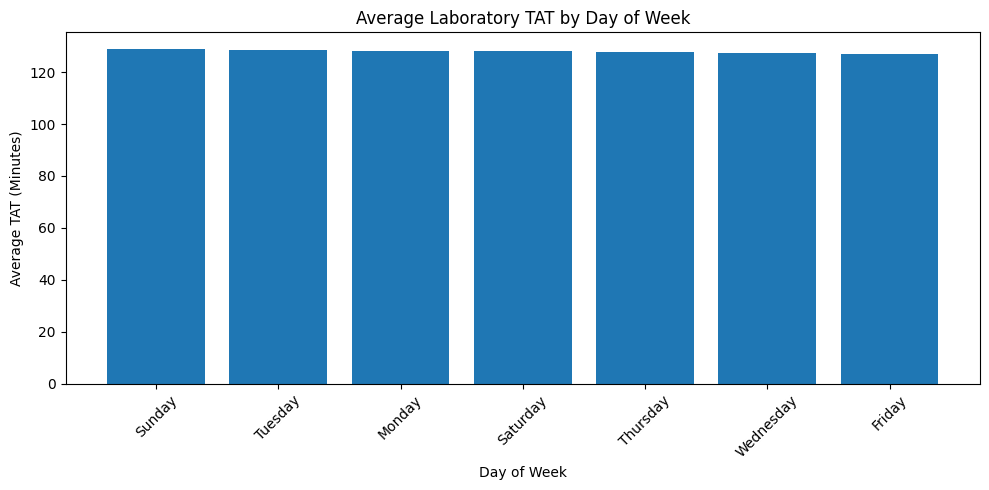

In [42]:
import matplotlib.pyplot as plt

weekday_tat_sorted = weekday_tat.sort_values(
    by='mean',
    ascending=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    weekday_tat_sorted.index,
    weekday_tat_sorted['mean']
)

plt.title('Average Laboratory TAT by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average TAT (Minutes)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

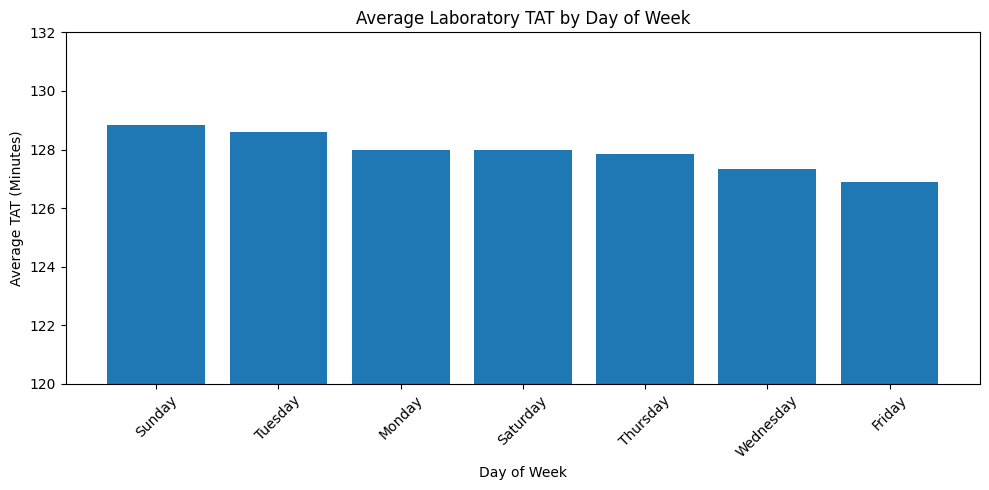

In [43]:
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_tat_sorted.index,
    weekday_tat_sorted['mean']
)

plt.ylim(120, 132)

plt.title('Average Laboratory TAT by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average TAT (Minutes)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [44]:
test_weekday_tat = (
    lab_results
    .groupby(['test_name', 'day_of_week'])['tat_minutes']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

test_weekday_tat

count    mean  median
test_name day_of_week                       
ALT       Friday         751  125.43  125.37
          Monday         746  127.30  129.37
          Saturday       656  127.80  128.32
          Sunday         751  126.19  126.23
          Thursday       732  127.31  125.82
...                      ...     ...     ...
eGFR      Saturday       709  129.69  130.20
          Sunday         703  125.42  125.97
          Thursday       747  127.33  127.42
          Tuesday        737  130.46  131.87
          Wednesday      735  129.12  129.62

[98 rows x 3 columns]

In [45]:
# Highest average TAT combinations
highest_test_tat = test_weekday_tat.sort_values(
    by='mean',
    ascending=False
)

print("Top 10 highest TAT combinations:")
display(highest_test_tat.head(10))

Top 10 highest TAT combinations:


,,count,mean,median
test_name,day_of_week,,,
Hemoglobin,Sunday,756,132.22,135.04
eGFR,Monday,733,131.27,133.55
CRP,Tuesday,747,131.14,131.43
Platelets,Saturday,677,131.11,129.17
Sodium,Thursday,703,130.71,131.03
Bilirubin,Tuesday,709,130.64,128.93
Sodium,Sunday,696,130.61,134.25
Glucose,Sunday,726,130.58,132.22
Bilirubin,Saturday,675,130.52,129.88


In [47]:
lowest_test_tat = test_weekday_tat.sort_values(
    by='mean',
    ascending=True
)

print("Top 10 lowest TAT combinations:")
display(lowest_test_tat.head(10))

Top 10 lowest TAT combinations:


,,count,mean,median
test_name,day_of_week,,,
ALT,Wednesday,767,123.77,124.68
Creatinine,Friday,662,124.01,123.58
Troponin,Friday,710,124.17,121.62
AST,Monday,675,124.73,126.88
WBC,Thursday,727,124.79,123.13
eGFR,Sunday,703,125.42,125.97
ALT,Friday,751,125.43,125.37
CBC,Thursday,714,125.50,126.58
WBC,Saturday,728,125.51,124.79


In [48]:
print("Top 10 lowest TAT combinations:")
display(lowest_test_tat.head(10))

Top 10 lowest TAT combinations:


,,count,mean,median
test_name,day_of_week,,,
ALT,Wednesday,767,123.77,124.68
Creatinine,Friday,662,124.01,123.58
Troponin,Friday,710,124.17,121.62
AST,Monday,675,124.73,126.88
WBC,Thursday,727,124.79,123.13
eGFR,Sunday,703,125.42,125.97
ALT,Friday,751,125.43,125.37
CBC,Thursday,714,125.50,126.58
WBC,Saturday,728,125.51,124.79


In [49]:
test_tat_range = (
    test_weekday_tat
    .groupby(level='test_name')['mean']
    .agg(['min', 'max'])
)

test_tat_range['tat_difference'] = (
    test_tat_range['max'] - test_tat_range['min']
)

test_tat_range = test_tat_range.sort_values(
    by='tat_difference',
    ascending=False
)

test_tat_range.round(2)

,min,max,tat_difference
test_name,,,
Creatinine,124.01,130.51,6.50
Hemoglobin,126.05,132.22,6.17
eGFR,125.42,131.27,5.85
ALT,123.77,129.30,5.53
Bilirubin,125.58,130.64,5.06
Glucose,125.54,130.58,5.04
CRP,126.25,131.14,4.89
CBC,125.50,130.29,4.79
Sodium,125.99,130.71,4.72


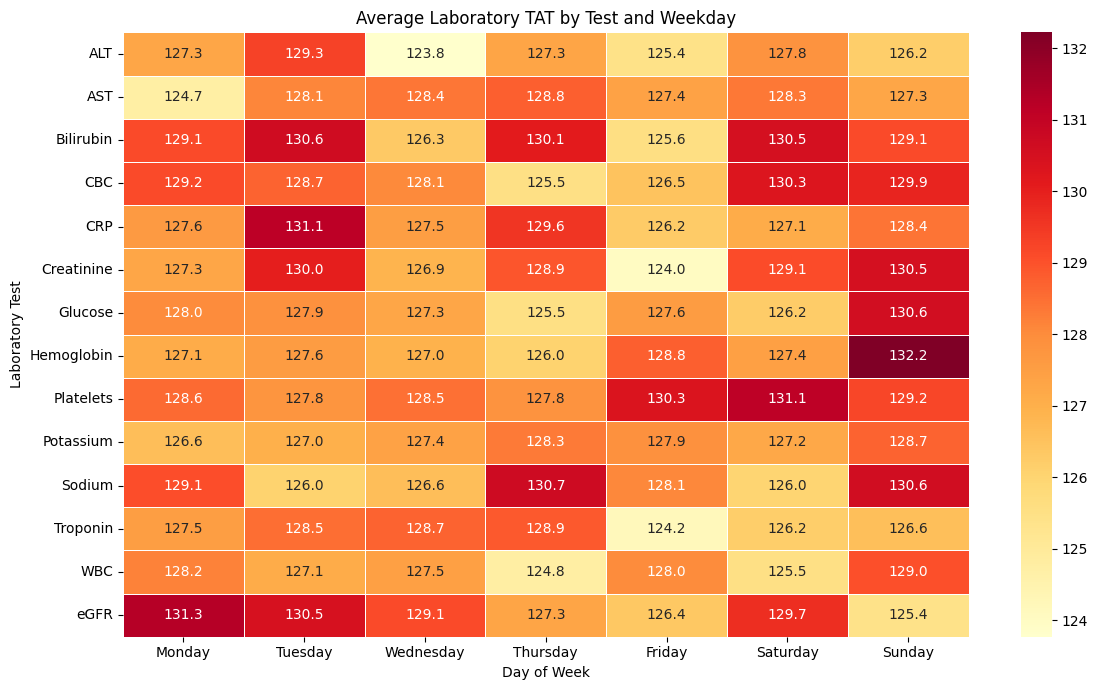

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

# Convert the grouped data into a matrix
heatmap_data = test_weekday_tat['mean'].unstack()

# Arrange weekdays in correct order
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

heatmap_data = heatmap_data[day_order]

# Create heatmap
plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Average Laboratory TAT by Test and Weekday')
plt.xlabel('Day of Week')
plt.ylabel('Laboratory Test')
plt.tight_layout()
plt.show()

In [51]:
# Create a delayed-sample indicator
lab_results['is_delayed'] = (
    lab_results['tat_minutes'] >= 180
)

# Calculate delay statistics by test
test_delay_analysis = (
    lab_results.groupby('test_name')['is_delayed']
    .agg(['count', 'sum', 'mean'])
)

# Convert proportion into percentage
test_delay_analysis['delay_percentage'] = (
    test_delay_analysis['mean'] * 100
)

# Sort by delay percentage
test_delay_analysis = test_delay_analysis.sort_values(
    by='delay_percentage',
    ascending=False
)

test_delay_analysis.round(2)

,count,sum,mean,delay_percentage
test_name,,,,
Platelets,5074,835,0.16,16.46
CRP,4998,819,0.16,16.39
Bilirubin,5033,814,0.16,16.17
Sodium,4974,793,0.16,15.94
WBC,5070,806,0.16,15.90
AST,5006,783,0.16,15.64
Creatinine,4997,778,0.16,15.57
Hemoglobin,5141,797,0.16,15.50
Glucose,5016,772,0.15,15.39


In [52]:
total_samples = lab_results.shape[0]

total_delayed = lab_results['is_delayed'].sum()

overall_delay_percentage = (
    total_delayed / total_samples
) * 100

print("Total Samples:", total_samples)
print("Delayed Samples:", total_delayed)
print("Overall Delay Percentage:", round(overall_delay_percentage, 2), "%")

Total Samples: 70635
Delayed Samples: 11014
Overall Delay Percentage: 15.59 %


In [53]:
weekday_delay_analysis = (
    lab_results.groupby('day_of_week')['is_delayed']
    .agg(['count', 'sum', 'mean'])
)

weekday_delay_analysis['delay_percentage'] = (
    weekday_delay_analysis['mean'] * 100
)

weekday_delay_analysis = weekday_delay_analysis.sort_values(
    by='delay_percentage',
    ascending=False
)

weekday_delay_analysis.round(2)

,count,sum,mean,delay_percentage
day_of_week,,,,
Tuesday,10213,1662,0.16,16.27
Thursday,10083,1599,0.16,15.86
Saturday,9871,1550,0.16,15.70
Sunday,10088,1570,0.16,15.56
Wednesday,10229,1587,0.16,15.51
Monday,10066,1549,0.15,15.39
Friday,10085,1497,0.15,14.84


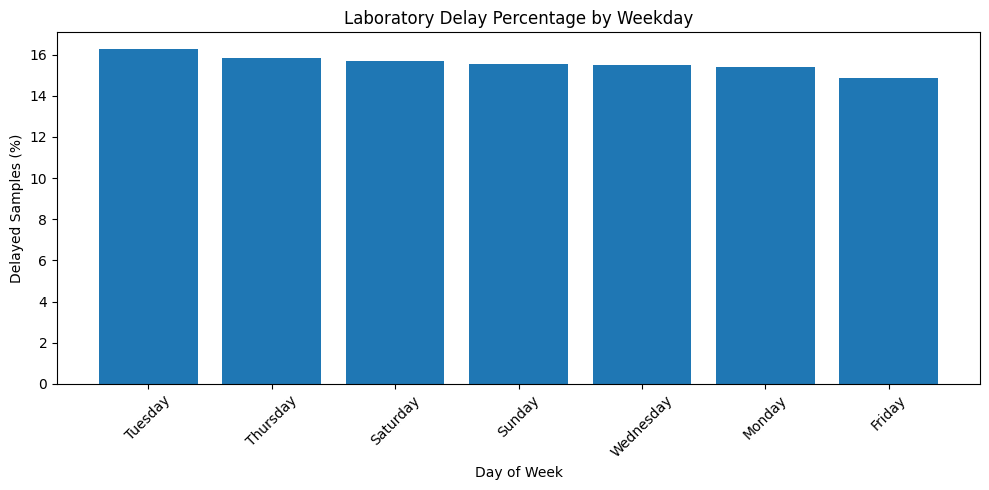

In [54]:
plt.figure(figsize=(10, 5))

weekday_delay_sorted = weekday_delay_analysis.sort_values(
    by='delay_percentage',
    ascending=False
)

plt.bar(
    weekday_delay_sorted.index,
    weekday_delay_sorted['delay_percentage']
)

plt.title('Laboratory Delay Percentage by Weekday')
plt.xlabel('Day of Week')
plt.ylabel('Delayed Samples (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [55]:
hourly_delay_analysis = (
    lab_results.groupby('collection_hour')['is_delayed']
    .agg(['count', 'sum', 'mean'])
)

hourly_delay_analysis['delay_percentage'] = (
    hourly_delay_analysis['mean'] * 100
)

hourly_delay_analysis = hourly_delay_analysis.sort_values(
    by='delay_percentage',
    ascending=False
)

hourly_delay_analysis.round(2)

,count,sum,mean,delay_percentage
collection_hour,,,,
5,952,174,0.18,18.28
2,1259,221,0.18,17.55
7,2232,379,0.17,16.98
6,1198,201,0.17,16.78
4,946,158,0.17,16.70
3,1146,190,0.17,16.58
20,3852,617,0.16,16.02
21,4012,640,0.16,15.95
9,3360,535,0.16,15.92


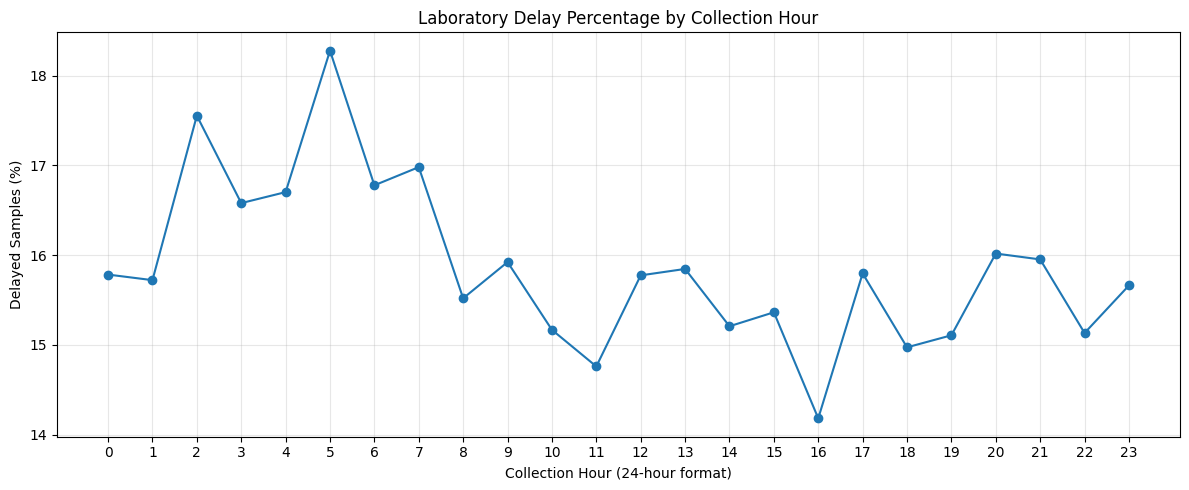

In [56]:
plt.figure(figsize=(12, 5))

hourly_delay_sorted = hourly_delay_analysis.sort_index()

plt.plot(
    hourly_delay_sorted.index,
    hourly_delay_sorted['delay_percentage'],
    marker='o'
)

plt.title('Laboratory Delay Percentage by Collection Hour')
plt.xlabel('Collection Hour (24-hour format)')
plt.ylabel('Delayed Samples (%)')

plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [57]:
weekday_hour_delay = (
    lab_results
    .groupby(['day_of_week', 'collection_hour'])['is_delayed']
    .mean()
    .mul(100)
    .unstack()
    .round(2)
)

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_hour_delay = weekday_hour_delay.reindex(day_order)

weekday_hour_delay

collection_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_of_week,,,,,,,,,,,,,,,,,,,,,
Monday,15.54,15.71,18.60,13.86,15.62,19.01,16.37,17.46,15.71,15.27,...,15.41,12.77,12.04,14.58,15.84,13.93,17.03,18.26,14.26,14.13
Tuesday,14.96,15.84,19.61,21.55,15.45,15.56,20.00,19.69,14.35,17.55,...,15.07,17.70,13.78,17.13,17.00,17.84,15.19,16.10,16.43,16.28
Wednesday,19.03,16.02,13.19,13.41,12.59,19.26,17.78,17.25,16.21,17.29,...,16.52,15.25,14.18,16.61,14.17,14.94,16.49,15.51,12.55,15.11
Thursday,15.93,10.11,20.48,17.06,19.42,16.43,14.67,17.99,17.93,14.85,...,16.52,17.33,15.68,15.65,14.26,13.85,16.54,14.95,17.42,15.32
Friday,15.00,17.04,11.70,13.01,21.74,18.32,16.09,17.57,14.97,17.06,...,11.86,14.09,13.04,14.67,15.32,12.18,15.18,12.68,15.66,16.57
Saturday,15.79,15.06,21.26,19.88,12.75,23.08,18.64,16.09,14.74,13.55,...,16.33,15.54,15.65,13.16,14.42,15.92,16.60,17.41,13.72,17.17
Sunday,14.29,20.00,17.89,16.34,19.84,16.55,13.45,12.70,14.50,15.90,...,14.67,14.80,14.93,18.73,13.93,16.83,15.17,16.75,15.89,15.19


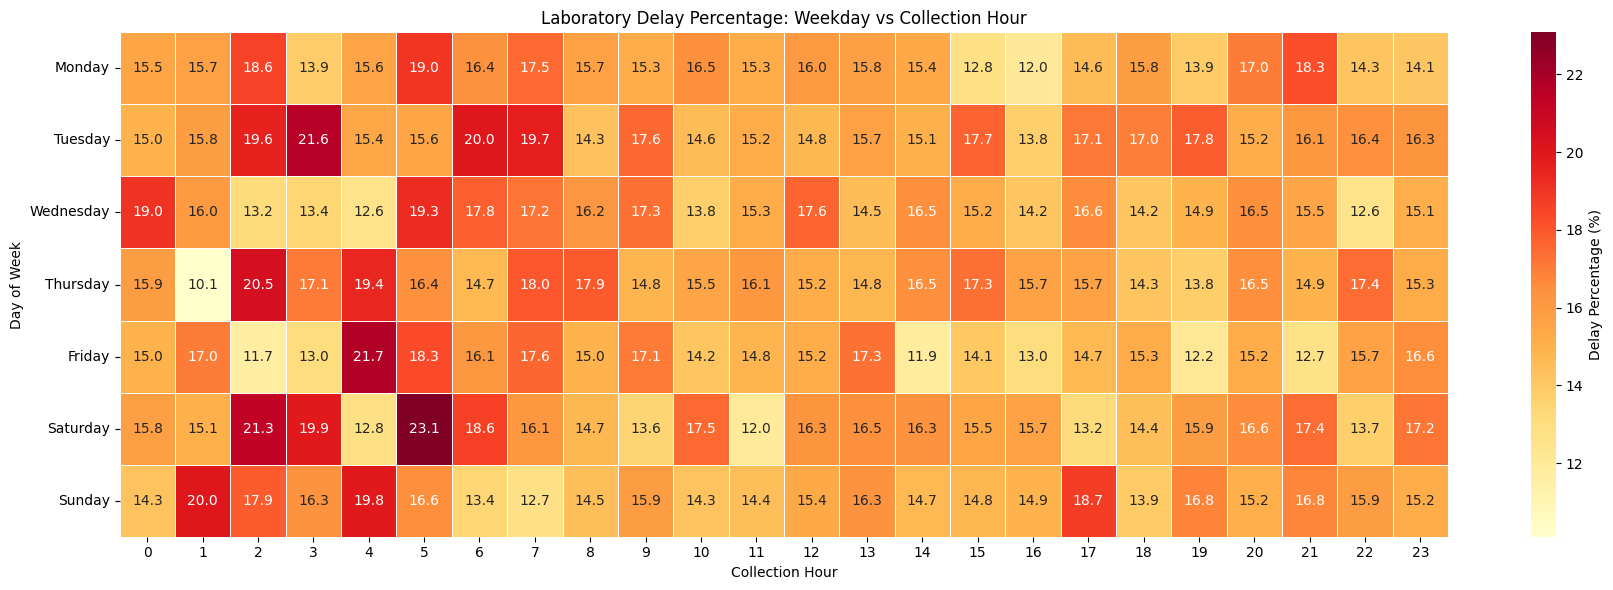

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 6))

sns.heatmap(
    weekday_hour_delay,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Delay Percentage (%)'}
)

plt.title('Laboratory Delay Percentage: Weekday vs Collection Hour')
plt.xlabel('Collection Hour')
plt.ylabel('Day of Week')

plt.tight_layout()
plt.show()

In [59]:
tat_percentiles = lab_results['tat_minutes'].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

print("TAT PERCENTILE ANALYSIS")
print(tat_percentiles)

TAT PERCENTILE ANALYSIS
0.50    128.250000
0.75    164.116667
0.90    191.900000
0.95    206.000000
0.99    224.811000
Name: tat_minutes, dtype: float64


In [60]:
Q1 = lab_results['tat_minutes'].quantile(0.25)
Q3 = lab_results['tat_minutes'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = lab_results[
    (lab_results['tat_minutes'] < lower_limit) |
    (lab_results['tat_minutes'] > upper_limit)
]

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Limit:", round(lower_limit, 2))
print("Upper Limit:", round(upper_limit, 2))

print("\nTotal Outliers:", len(outliers))
print("Outlier Percentage:", round(
    len(outliers) / len(lab_results) * 100, 2
), "%")

Q1: 91.42
Q3: 164.12
IQR: 72.7
Lower Limit: -17.63
Upper Limit: 273.17

Total Outliers: 0
Outlier Percentage: 0.0 %


In [61]:
lab_results['collection_month'] = (
    lab_results['collection_time'].dt.to_period('M')
)

In [62]:
monthly_tat = (
    lab_results.groupby('collection_month')
    .agg(
        total_samples=('tat_minutes', 'count'),
        average_tat=('tat_minutes', 'mean'),
        median_tat=('tat_minutes', 'median'),
        delayed_samples=('is_delayed', 'sum'),
        delay_rate=('is_delayed', 'mean')
    )
)

monthly_tat['delay_percentage'] = (
    monthly_tat['delay_rate'] * 100
)

monthly_tat = monthly_tat.drop(
    columns='delay_rate'
).round(2)

print(monthly_tat.to_string())

                  total_samples  average_tat  median_tat  delayed_samples  delay_percentage
collection_month                                                                           
2024-01                    2280       127.35      126.33              357             15.66
2024-02                    2271       128.18      130.48              350             15.41
2024-03                    2229       127.22      127.72              347             15.57
2024-04                    2297       127.10      126.50              366             15.93
2024-05                    2354       127.38      128.88              350             14.87
2024-06                    2348       125.93      126.51              326             13.88
2024-07                    2573       129.06      128.55              420             16.32
2024-08                    2344       130.56      131.24              389             16.60
2024-09                    2390       127.26      128.38              359       

In [63]:
print("TOP 5 MONTHS — HIGHEST DELAY RATE")

print(
    monthly_tat.sort_values(
        by='delay_percentage',
        ascending=False
    ).head(5).to_string()
)

print("\nTOP 5 MONTHS — LOWEST DELAY RATE")

print(
    monthly_tat.sort_values(
        by='delay_percentage',
        ascending=True
    ).head(5).to_string()
)

TOP 5 MONTHS — HIGHEST DELAY RATE
                  total_samples  average_tat  median_tat  delayed_samples  delay_percentage
collection_month                                                                           
2026-03                    2411       128.40      127.52              410             17.01
2026-04                    2291       128.70      129.02              385             16.80
2026-06                    2154       128.80      128.02              360             16.71
2024-08                    2344       130.56      131.24              389             16.60
2025-06                    2644       129.63      131.58              435             16.45

TOP 5 MONTHS — LOWEST DELAY RATE
                  total_samples  average_tat  median_tat  delayed_samples  delay_percentage
collection_month                                                                           
2026-07                      17       121.66      122.27                0              0.00
2024-06     

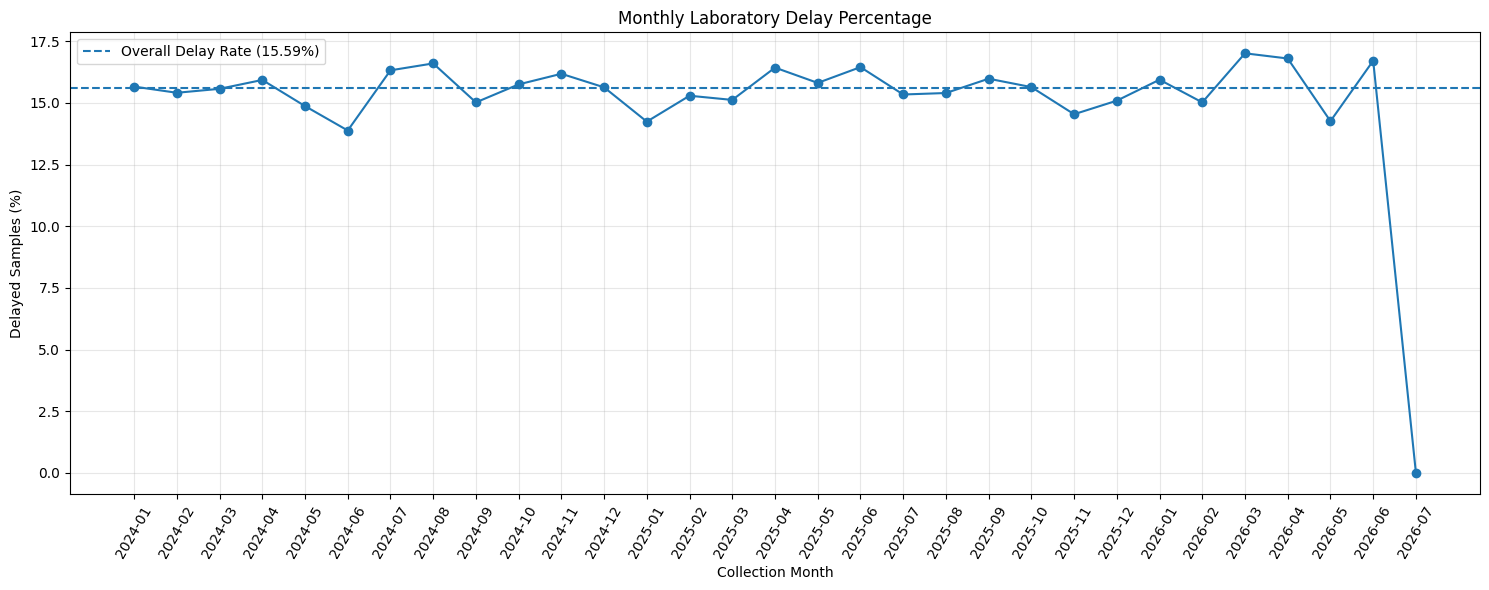

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_tat.index.astype(str),
    monthly_tat['delay_percentage'],
    marker='o'
)

plt.axhline(
    y=15.59,
    linestyle='--',
    label='Overall Delay Rate (15.59%)'
)

plt.title('Monthly Laboratory Delay Percentage')
plt.xlabel('Collection Month')
plt.ylabel('Delayed Samples (%)')

plt.xticks(rotation=60)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [65]:
monthly_workload = (
    lab_results.groupby('collection_month')
    .agg(
        total_samples=('tat_minutes', 'count'),
        average_tat=('tat_minutes', 'mean'),
        delayed_samples=('is_delayed', 'sum'),
        delay_percentage=('is_delayed', 'mean')
    )
)

monthly_workload['delay_percentage'] *= 100

monthly_workload = monthly_workload.round(2)

print(monthly_workload.to_string())

                  total_samples  average_tat  delayed_samples  delay_percentage
collection_month                                                               
2024-01                    2280       127.35              357             15.66
2024-02                    2271       128.18              350             15.41
2024-03                    2229       127.22              347             15.57
2024-04                    2297       127.10              366             15.93
2024-05                    2354       127.38              350             14.87
2024-06                    2348       125.93              326             13.88
2024-07                    2573       129.06              420             16.32
2024-08                    2344       130.56              389             16.60
2024-09                    2390       127.26              359             15.02
2024-10                    2349       128.38              370             15.75
2024-11                    2398       12

In [66]:
correlation = monthly_workload[
    ['total_samples', 'average_tat', 'delay_percentage']
].corr()

print(correlation.round(3))

                  total_samples  average_tat  delay_percentage
total_samples             1.000        0.748             0.924
average_tat               0.748        1.000             0.848
delay_percentage          0.924        0.848             1.000


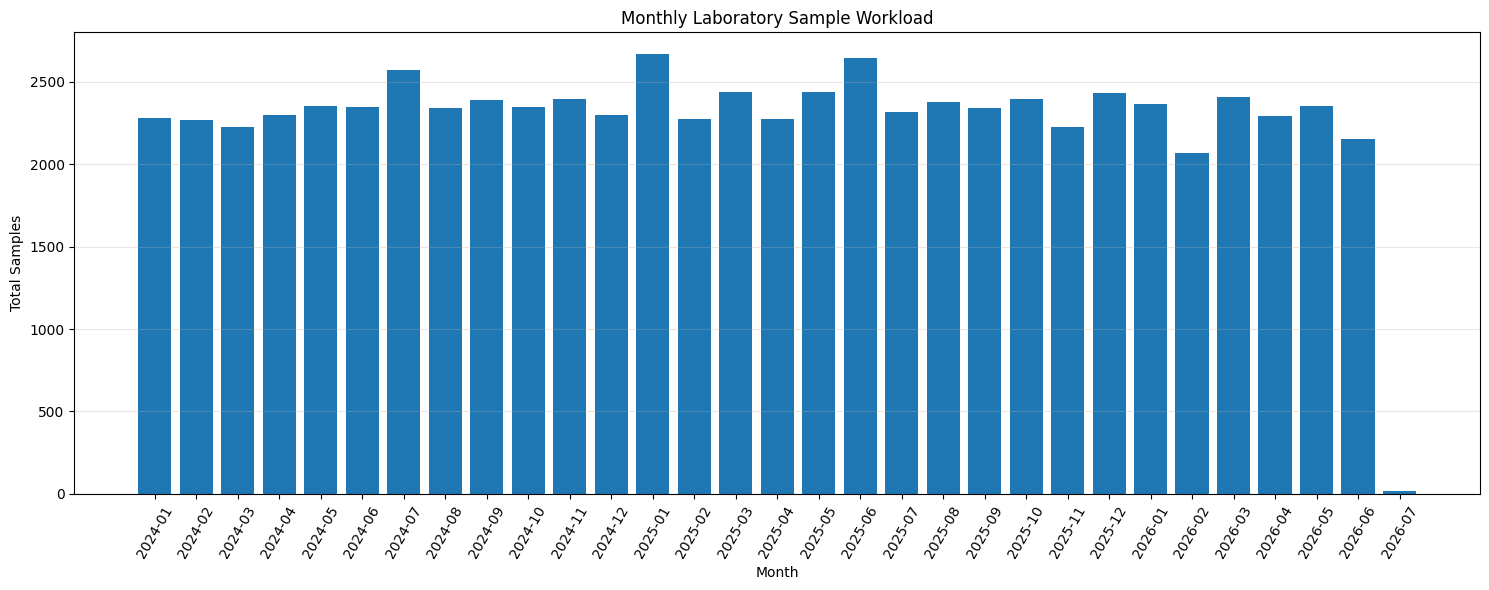

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.bar(
    monthly_workload.index.astype(str),
    monthly_workload['total_samples']
)

plt.title('Monthly Laboratory Sample Workload')
plt.xlabel('Month')
plt.ylabel('Total Samples')

plt.xticks(rotation=60)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [68]:
print(
    monthly_workload.sort_values(
        by='total_samples',
        ascending=False
    ).head(5).to_string()
)

                  total_samples  average_tat  delayed_samples  delay_percentage
collection_month                                                               
2025-01                    2668       127.93              380             14.24
2025-06                    2644       129.63              435             16.45
2024-07                    2573       129.06              420             16.32
2025-05                    2441       128.43              386             15.81
2025-03                    2440       127.22              369             15.12


In [70]:
lab_results['sla_status'] = (
    lab_results['tat_minutes'] <= 180
).map({
    True: 'Within SLA',
    False: 'Breached SLA'
})

In [71]:
sla_summary = (
    lab_results['sla_status']
    .value_counts()
    .to_frame('sample_count')
)

sla_summary['percentage'] = (
    sla_summary['sample_count']
    / len(lab_results) * 100
)

print(sla_summary.round(2))

              sample_count  percentage
sla_status                            
Within SLA           59629       84.42
Breached SLA         11006       15.58


In [72]:
test_sla = (
    lab_results.groupby('test_name')
    .agg(
        total_samples=('tat_minutes', 'count'),
        within_sla=('sla_status',
                    lambda x: (x == 'Within SLA').sum())
    )
)

test_sla['sla_percentage'] = (
    test_sla['within_sla']
    / test_sla['total_samples'] * 100
)

test_sla = test_sla.sort_values(
    by='sla_percentage',
    ascending=True
).round(2)

print(test_sla.to_string())

            total_samples  within_sla  sla_percentage
test_name                                            
Platelets            5074        4240           83.56
CRP                  4998        4179           83.61
Bilirubin            5033        4219           83.83
Sodium               4974        4181           84.06
WBC                  5070        4264           84.10
AST                  5006        4224           84.38
Creatinine           4997        4219           84.43
Hemoglobin           5141        4346           84.54
Glucose              5016        4247           84.67
CBC                  5043        4272           84.71
ALT                  5115        4334           84.73
Potassium            4909        4164           84.82
eGFR                 5102        4331           84.89
Troponin             5157        4409           85.50


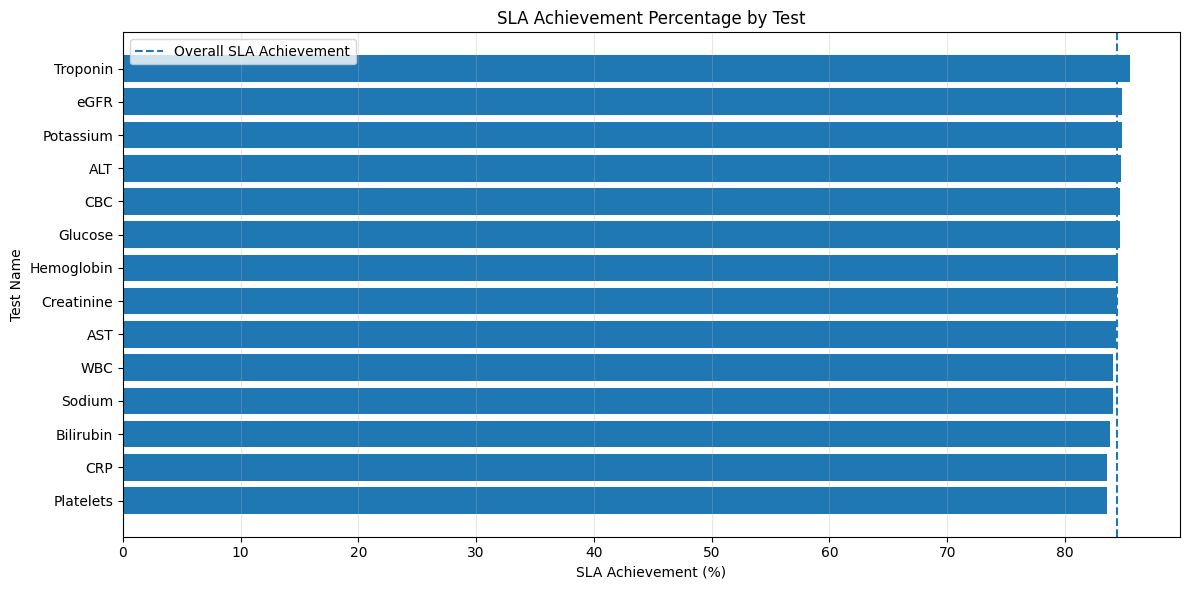

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    test_sla.index,
    test_sla['sla_percentage']
)

plt.axvline(
    x=84.41,
    linestyle='--',
    label='Overall SLA Achievement'
)

plt.title('SLA Achievement Percentage by Test')
plt.xlabel('SLA Achievement (%)')
plt.ylabel('Test Name')

plt.legend()
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [74]:
print(test_sla.sort_values(
    by='sla_percentage',
    ascending=True
).to_string())

            total_samples  within_sla  sla_percentage
test_name                                            
Platelets            5074        4240           83.56
CRP                  4998        4179           83.61
Bilirubin            5033        4219           83.83
Sodium               4974        4181           84.06
WBC                  5070        4264           84.10
AST                  5006        4224           84.38
Creatinine           4997        4219           84.43
Hemoglobin           5141        4346           84.54
Glucose              5016        4247           84.67
CBC                  5043        4272           84.71
ALT                  5115        4334           84.73
Potassium            4909        4164           84.82
eGFR                 5102        4331           84.89
Troponin             5157        4409           85.50


In [75]:
test_percentiles = (
    lab_results.groupby('test_name')['tat_minutes']
    .quantile([0.50, 0.90, 0.95])
    .unstack()
)

test_percentiles.columns = [
    'P50_median',
    'P90',
    'P95'
]

test_percentiles = test_percentiles.round(2)

print(
    test_percentiles.sort_values(
        by='P95',
        ascending=False
    ).to_string()
)

            P50_median     P90     P95
test_name                             
CBC             129.45  191.11  207.06
Hemoglobin      128.30  191.88  207.05
Platelets       128.82  193.66  207.05
CRP             128.14  194.40  206.94
WBC             126.57  192.72  206.88
Sodium          128.79  192.73  206.22
eGFR            129.00  190.82  205.98
Bilirubin       128.58  192.41  205.95
Potassium       128.62  190.73  205.41
Glucose         127.73  191.07  205.20
ALT             126.97  191.36  205.07
AST             127.68  191.92  205.05
Creatinine      129.03  191.52  204.65
Troponin        127.62  190.08  204.41


In [76]:
delay_contribution = (
    lab_results.groupby('test_name')
    .agg(
        total_samples=('tat_minutes', 'count'),
        delayed_samples=('is_delayed', 'sum')
    )
)

delay_contribution['delay_rate'] = (
    delay_contribution['delayed_samples']
    / delay_contribution['total_samples'] * 100
)

delay_contribution['contribution_percentage'] = (
    delay_contribution['delayed_samples']
    / lab_results['is_delayed'].sum() * 100
)

delay_contribution = delay_contribution.sort_values(
    by='delayed_samples',
    ascending=False
).round(2)

print(delay_contribution.to_string())

            total_samples  delayed_samples  delay_rate  contribution_percentage
test_name                                                                      
Platelets            5074              835       16.46                     7.58
CRP                  4998              819       16.39                     7.44
Bilirubin            5033              814       16.17                     7.39
WBC                  5070              806       15.90                     7.32
Hemoglobin           5141              797       15.50                     7.24
Sodium               4974              793       15.94                     7.20
AST                  5006              783       15.64                     7.11
ALT                  5115              781       15.27                     7.09
Creatinine           4997              778       15.57                     7.06
eGFR                 5102              772       15.13                     7.01
Glucose              5016              7

In [77]:
# Recalculate delayed status directly from TAT
lab_results['delay_check'] = lab_results['tat_minutes'] > 180

# Count records where the two delay flags disagree
mismatch_count = (
    lab_results['is_delayed'] != lab_results['delay_check']
).sum()

print("Total mismatched records:", mismatch_count)

# Compare both flags
print(pd.crosstab(
    lab_results['is_delayed'],
    lab_results['delay_check']
))

Total mismatched records: 8
delay_check  False  True 
is_delayed               
False        59621      0
True             8  11006


In [78]:
mismatched_records = lab_results[
    lab_results['is_delayed'] != lab_results['delay_check']
]

print(
    mismatched_records[
        ['test_name', 'tat_minutes', 'is_delayed', 'delay_check']
    ].to_string()
)

         test_name  tat_minutes  is_delayed  delay_check
198103     Glucose        180.0        True        False
203117     Glucose        180.0        True        False
226503   Platelets        180.0        True        False
233940         AST        180.0        True        False
386405     Glucose        180.0        True        False
503528        eGFR        180.0        True        False
596362  Hemoglobin        180.0        True        False
671042  Hemoglobin        180.0        True        False


In [79]:
# Correct the delay classification
lab_results['is_delayed'] = lab_results['tat_minutes'] > 180

# Verify the corrected count
print("Total delayed samples:", lab_results['is_delayed'].sum())

print("Delay percentage:",
      round(lab_results['is_delayed'].mean() * 100, 2), "%")

Total delayed samples: 11006
Delay percentage: 15.58 %


In [80]:
lab_results['delay_check'] = lab_results['tat_minutes'] > 180

print(
    "Remaining mismatches:",
    (lab_results['is_delayed'] != lab_results['delay_check']).sum()
)

Remaining mismatches: 0


In [81]:
overall_summary = pd.DataFrame({
    'Metric': [
        'Total Samples',
        'Average TAT',
        'Median TAT',
        'Minimum TAT',
        'Maximum TAT',
        'Delayed Samples',
        'Delay Percentage',
        'Within SLA Samples',
        'SLA Achievement Percentage'
    ],
    'Value': [
        len(lab_results),
        round(lab_results['tat_minutes'].mean(), 2),
        round(lab_results['tat_minutes'].median(), 2),
        round(lab_results['tat_minutes'].min(), 2),
        round(lab_results['tat_minutes'].max(), 2),
        lab_results['is_delayed'].sum(),
        round(lab_results['is_delayed'].mean() * 100, 2),
        (lab_results['sla_status'] == 'Within SLA').sum(),
        round(
            (lab_results['sla_status'] == 'Within SLA').mean() * 100, 2
        )
    ]
})

print(overall_summary.to_string(index=False))

                    Metric    Value
             Total Samples 70635.00
               Average TAT   127.93
                Median TAT   128.25
               Minimum TAT    25.30
               Maximum TAT   239.53
           Delayed Samples 11006.00
          Delay Percentage    15.58
        Within SLA Samples 59629.00
SLA Achievement Percentage    84.42


In [82]:
test_insights = (
    lab_results.groupby('test_name')
    .agg(
        total_samples=('tat_minutes', 'count'),
        delayed_samples=('is_delayed', 'sum')
    )
)

test_insights['delay_rate'] = (
    test_insights['delayed_samples']
    / test_insights['total_samples'] * 100
)

test_insights['delay_contribution'] = (
    test_insights['delayed_samples']
    / lab_results['is_delayed'].sum() * 100
)

test_insights = test_insights.sort_values(
    by='delayed_samples',
    ascending=False
).round(2)

print(test_insights.to_string())

            total_samples  delayed_samples  delay_rate  delay_contribution
test_name                                                                 
Platelets            5074              834       16.44                7.58
CRP                  4998              819       16.39                7.44
Bilirubin            5033              814       16.17                7.40
WBC                  5070              806       15.90                7.32
Hemoglobin           5141              795       15.46                7.22
Sodium               4974              793       15.94                7.21
AST                  5006              782       15.62                7.11
ALT                  5115              781       15.27                7.10
Creatinine           4997              778       15.57                7.07
CBC                  5043              771       15.29                7.01
eGFR                 5102              771       15.11                7.01
Glucose              5016

In [83]:
hourly_insights = (
    lab_results.groupby('collection_hour')
    .agg(
        total_samples=('tat_minutes', 'count'),
        delayed_samples=('is_delayed', 'sum'),
        average_tat=('tat_minutes', 'mean')
    )
)

hourly_insights['delay_rate'] = (
    hourly_insights['delayed_samples']
    / hourly_insights['total_samples'] * 100
)

hourly_insights = hourly_insights.sort_values(
    by='delay_rate',
    ascending=False
).round(2)

print(hourly_insights.to_string())

                 total_samples  delayed_samples  average_tat  delay_rate
collection_hour                                                         
5                          952              174       130.95       18.28
2                         1259              221       134.02       17.55
7                         2232              378       130.26       16.94
6                         1198              201       131.78       16.78
4                          946              158       132.53       16.70
3                         1146              188       130.45       16.40
20                        3852              616       127.85       15.99
21                        4012              640       127.69       15.95
9                         3360              533       127.90       15.86
13                        4001              634       128.16       15.85
17                        3906              617       128.17       15.80
0                         1698              268    

In [84]:
weekday_hour_analysis = lab_results.pivot_table(
    index='day_of_week',
    columns='collection_hour',
    values='is_delayed',
    aggfunc='mean'
) * 100

weekday_hour_analysis = weekday_hour_analysis.round(2)

print(weekday_hour_analysis.to_string())

collection_hour     0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23
day_of_week                                                                                                                                                                            
Friday           15.00  17.04  11.70  13.01  21.74  18.32  16.09  17.25  14.97  17.06  14.21  14.85  15.21  17.27  11.86  14.09  13.04  14.67  15.32  12.18  15.18  12.68  15.66  16.57
Monday           15.54  15.71  18.60  13.86  15.62  19.01  16.37  17.46  15.71  15.27  16.48  15.32  16.04  15.83  15.41  12.77  12.04  14.58  15.84  13.93  17.03  18.26  14.26  14.13
Saturday         15.79  14.64  21.26  19.88  12.75  23.08  18.64  16.09  14.74  13.55  17.46  12.00  16.26  16.49  16.33  15.54  15.65  13.16  14.42  15.92  16.60  17.41  13.72  17.17
Sunday           14.29  20.00  17.89  16.34  19.84  16.55  13.45  12.70  14.50  

In [85]:
weekday_hour_counts = lab_results.pivot_table(
    index='day_of_week',
    columns='collection_hour',
    values='tat_minutes',
    aggfunc='count',
    fill_value=0
)

weekday_hour_delays = lab_results.pivot_table(
    index='day_of_week',
    columns='collection_hour',
    values='is_delayed',
    aggfunc='sum',
    fill_value=0
)

print("Sample counts:")
print(weekday_hour_counts.to_string())

print("\nDelayed sample counts:")
print(weekday_hour_delays.to_string())

Sample counts:
collection_hour   0    1    2    3    4    5    6    7    8    9    10   11   12   13   14   15   16   17   18   19   20   21   22   23
day_of_week                                                                                                                            
Friday           240  223  171  146  138  131  174  313  394  469  556  532  559  579  565  582  598  552  568  583  560  560  530  362
Monday           251  191  172  166  128  142  171  315  401  491  522  496  555  556  584  564  573  535  587  596  552  575  568  375
Saturday         228  239  174  166  149  130  177  317  441  465  481  525  529  558  539  547  543  570  548  559  530  563  532  361
Sunday           252  195  190  153  126  139  171  315  462  497  511  541  540  545  525  527  576  550  603  606  567  567  535  395
Thursday         226  188  166  170  139  140  150  339  474  485  509  553  546  594  575  531  593  543  554  527  520  602  574  385
Tuesday          254  221  204  1

In [86]:
lab_results.to_csv("labpulse_cleaned.csv", index=False)

In [87]:


# Create a copy of the cleaned dataset
export_df = lab_results.copy()

# Convert Boolean values into integers
export_df['is_delayed'] = export_df['is_delayed'].astype(int)

# Export the corrected dataset
export_df.to_csv("labpulse_cleaned.csv", index=False)

print("CSV exported successfully!")
print(export_df['is_delayed'].value_counts())

CSV exported successfully!
is_delayed
0    59629
1    11006
Name: count, dtype: int64


In [88]:
print("Shape:", export_df.shape)

print("\nColumn names:")
print(export_df.columns.tolist())

Shape: (70635, 69)

Column names:
['event_id', 'patient_id', 'encounter_id', 'event_date', 'event_time', 'event_type', 'event_category', 'source_system', 'destination_system', 'department', 'provider_role', 'event_status', 'event_priority', 'order_id', 'result_id', 'procedure_id', 'transfer_id', 'test_name', 'specimen_type', 'collection_time', 'processing_time', 'result_time', 'result_value', 'result_unit', 'reference_range', 'abnormal_flag', 'result_status', 'imaging_modality', 'body_region', 'scheduled_time', 'performed_time', 'report_time', 'report_status', 'result_category', 'medication_category', 'dose_category', 'route', 'frequency', 'order_time', 'verification_time', 'dispense_time', 'administration_time', 'medication_status', 'discontinuation_reason', 'procedure_category', 'request_time', 'completion_status', 'from_department', 'to_department', 'transfer_reason', 'bed_category', 'completion_time', 'transfer_status', 'message_type', 'transmission_time', 'acknowledgement_status',

In [89]:
print(export_df['is_delayed'].dtype)
print(export_df['is_delayed'].value_counts())
print(export_df['is_delayed'].unique())

int64
is_delayed
0    59629
1    11006
Name: count, dtype: int64
[0 1]


In [90]:
csv_path = r"C:\Users\Mohit\OneDrive\Desktop\Projects\LabPulse\notebooks\labpulse_cleaned.csv"

with open(csv_path, "rb") as f:
    print(repr(f.readline()))

b'event_id,patient_id,encounter_id,event_date,event_time,event_type,event_category,source_system,destination_system,department,provider_role,event_status,event_priority,order_id,result_id,procedure_id,transfer_id,test_name,specimen_type,collection_time,processing_time,result_time,result_value,result_unit,reference_range,abnormal_flag,result_status,imaging_modality,body_region,scheduled_time,performed_time,report_time,report_status,result_category,medication_category,dose_category,route,frequency,order_time,verification_time,dispense_time,administration_time,medication_status,discontinuation_reason,procedure_category,request_time,completion_status,from_department,to_department,transfer_reason,bed_category,completion_time,transfer_status,message_type,transmission_time,acknowledgement_status,processing_status,error_status,retry_count,tat,tat_minutes,collection_date,collection_hour,day_of_week,day_type,is_delayed,collection_month,sla_status,delay_check\r\n'
